# Rekurzivní algoritmy: rozděl a panuj – řešení úloh


In [1]:
from pathlib import Path
import sys
import platform
import importlib
import math
import random
from IPython.display import display, Markdown
print('Python:', platform.python_version())
print('Limit rekurze:', sys.getrecursionlimit())
print('Pracovní složka:', Path.cwd())


Python: 3.15.0
Limit rekurze: 1000
Pracovní složka: D:\Programko\UJEP\PDSA\27_10_2026


## sorting.py
Vlastní řazení; volitelné statistiky počítají skutečná porovnání. Hloubka zahrnuje kořen (1) a základní volání.

In [2]:
%%writefile sorting.py
"""Řazení; statistiky se sbírají pouze při předání slovníku stats."""
import random

def comparison(stats, count=1):
    if stats is not None:
        stats['operations'] = stats.get('operations', 0) + count

def depth(stats, level):
    if stats is not None:
        stats['depth'] = max(stats.get('depth', 0), level)

def merge_sort(data, stats=None, key=lambda x: x, level=1):
    depth(stats, level)
    if len(data) <= 1:
        return list(data)
    mid = len(data) // 2
    left = merge_sort(data[:mid], stats, key, level+1)
    right = merge_sort(data[mid:], stats, key, level+1)
    result, i, j = [], 0, 0
    while i < len(left) and j < len(right):
        comparison(stats)
        if key(left[i]) <= key(right[j]):  # Shoda: přednost má levá část.
            result.append(left[i]); i += 1
        else:
            result.append(right[j]); j += 1
    return result + left[i:] + right[j:]

def quick_sort(data, stats=None, pivot='random', rng=None, level=1):
    if pivot not in ('first', 'random'):
        raise ValueError('Pivot musí být first nebo random.')
    if rng is None:
        rng = random.Random(42)
    depth(stats, level)
    if len(data) <= 1:
        return list(data)
    p = data[0] if pivot == 'first' else rng.choice(data)
    left, equal, right = [], [], []
    for x in data:
        comparison(stats)
        if x < p:
            left.append(x)
        else:
            comparison(stats)  # Počítáme i druhé skutečně provedené porovnání.
            if x == p:
                equal.append(x)
            else:
                right.append(x)
    return (quick_sort(left, stats, pivot, rng, level+1) + equal
            + quick_sort(right, stats, pivot, rng, level+1))

def bubble_sort(data, stats=None):
    a = list(data)
    for end in range(len(a)-1, 0, -1):
        changed = False
        for i in range(end):
            comparison(stats)
            if a[i] > a[i+1]:
                a[i], a[i+1] = a[i+1], a[i]
                changed = True
        if not changed:  # Používáme předčasné ukončení.
            break
    return a

def shaker_sort(data, stats=None):
    a = list(data)
    lo, hi = 0, len(a)-1
    while lo < hi:
        changed = False
        for i in range(lo, hi):
            comparison(stats)
            if a[i] > a[i+1]:
                a[i], a[i+1] = a[i+1], a[i]; changed = True
        hi -= 1
        if not changed:
            break
        changed = False
        for i in range(hi, lo, -1):
            comparison(stats)
            if a[i-1] > a[i]:
                a[i-1], a[i] = a[i], a[i-1]; changed = True
        lo += 1
        if not changed:
            break
    return a


Writing sorting.py


## hanoi.py
Implementace podle zadání.

In [3]:
%%writefile hanoi.py
def hanoi(n, source='A', target='B', auxiliary='C'):
    """Generuje tahy (zdroj, cíl); n musí být nezáporné celé číslo."""
    if not isinstance(n, int) or n < 0:
        raise ValueError('n musí být nezáporné celé číslo')
    if n:
        yield from hanoi(n-1, source, auxiliary, target)
        yield source, target
        yield from hanoi(n-1, auxiliary, target, source)

def verify_hanoi(n):
    rods = {'A': list(range(n, 0, -1)), 'B': [], 'C': []}
    moves = list(hanoi(n))
    for source, target in moves:
        assert rods[source], 'Prázdná zdrojová tyč'
        disk = rods[source].pop()
        assert not rods[target] or rods[target][-1] > disk, 'Větší disk na menším'
        rods[target].append(disk)
    assert rods == {'A': [], 'B': list(range(n, 0, -1)), 'C': []}
    assert len(moves) == 2**n-1
    return len(moves)


Writing hanoi.py


## closest.py
Vzdálenosti porovnáváme ve čtverci, odmocninu počítáme až při návratu. Řazení podle y vzniká pouze jednou; rekurze zachovává pořadí. Počítáme vyhodnocení eukleidovské vzdálenosti dvojic, nikoli řadicí porovnání nebo testy pásu.

In [4]:
%%writefile closest.py
from math import sqrt
from sorting import comparison, depth

def distance2(a, b, stats):
    comparison(stats)
    return (a[0]-b[0])**2 + (a[1]-b[1])**2

def brute_force(points, stats=None):
    if len(points) < 2:
        raise ValueError('Je nutné zadat alespoň dva body.')
    best, pair = float('inf'), None
    for i in range(len(points)):
        for j in range(i+1, len(points)):
            d = distance2(points[i], points[j], stats)
            if d < best:
                best, pair = d, (points[i], points[j])
    return sqrt(best), pair

def closest_pair(points, stats=None):
    if len(points) < 2:
        raise ValueError('Je nutné zadat alespoň dva body.')
    # ID odliší i různé vstupní body se shodnými souřadnicemi.
    px = sorted((x, y, i) for i, (x, y) in enumerate(points))
    py = sorted(px, key=lambda p: (p[1], p[0], p[2]))
    def solve(xs, ys, level):
        depth(stats, level)
        if len(xs) <= 3:
            best, pair = float('inf'), None
            for i in range(len(xs)):
                for j in range(i+1, len(xs)):
                    d = distance2(xs[i], xs[j], stats)
                    if d < best:
                        best, pair = d, (xs[i], xs[j])
            return best, pair
        mid = len(xs)//2
        left, right = xs[:mid], xs[mid:]
        ids = {p[2] for p in left}
        ly, ry = [], []
        for p in ys:
            (ly if p[2] in ids else ry).append(p)
        dl, pl = solve(left, ly, level+1)
        dr, pr = solve(right, ry, level+1)
        best, pair = (dl, pl) if dl <= dr else (dr, pr)
        if best == 0:
            return best, pair
        border = right[0][0]
        strip = [p for p in ys if (p[0]-border)**2 < best]
        for i in range(len(strip)):
            for j in range(i+1, min(i+8, len(strip))):
                if (strip[j][1]-strip[i][1])**2 >= best:
                    break
                d = distance2(strip[i], strip[j], stats)
                if d < best:
                    best, pair = d, (strip[i], strip[j])
        return best, pair
    best, pair = solve(px, py, 1)
    return sqrt(best), tuple((p[0], p[1]) for p in pair)


Writing closest.py


## multiplication.py
Implementace podle zadání.

In [5]:
%%writefile multiplication.py
def validate(x, y):
    if not isinstance(x, int) or not isinstance(y, int) or x < 0 or y < 0:
        raise ValueError('Očekávám dvě nezáporná celá čísla.')

def karatsuba(x, y):
    validate(x, y)
    def rec(a, b):
        if a < 10 or b < 10:
            return a*b
        m = max(len(str(a)), len(str(b))) // 2
        base = 10**m
        ah, al = divmod(a, base)
        bh, bl = divmod(b, base)
        z2, z0 = rec(ah, bh), rec(al, bl)
        z1 = rec(ah+al, bh+bl) - z2 - z0
        return z2*base**2 + z1*base + z0
    return rec(x, y)

def school_multiply(x, y):
    validate(x, y)
    a, b = list(map(int, str(x)[::-1])), list(map(int, str(y)[::-1]))
    digits = [0]*(len(a)+len(b))
    for i, u in enumerate(a):
        for j, v in enumerate(b):
            digits[i+j] += u*v
    for i in range(len(digits)-1):
        carry, digits[i] = divmod(digits[i], 10)
        digits[i+1] += carry
    result = 0
    for digit in reversed(digits):
        result = result*10 + digit
    return result


Writing multiplication.py


## main.py
Pevný seed 42, jeden zahřívací a sedm měřených běhů, medián. Náhodný pivot má pro opakovatelnost v každém běhu stejný seed. Limit rekurze nezvyšujeme; selhání evidujeme. Čas zahrnuje režii volitelných kontrol počítadel, samotná počítadla jsou aktivní až v odděleném běhu.

In [6]:
%%writefile main.py
"""Příprava dat a férové experimenty. Spuštění: python main.py."""
import csv
import math
import random
import sys
from pathlib import Path
from statistics import median
from time import perf_counter
from sorting import merge_sort, quick_sort, bubble_sort, shaker_sort
from closest import brute_force, closest_pair
from multiplication import karatsuba, school_multiply

SIZES = (100, 300, 1000, 3000)

def measure(fn, data, check, repeats=7):
    # Kopie, kontrola i generování dat leží mimo měřený úsek.
    fn(list(data))  # Zahřívací běh.
    times = []
    for _ in range(repeats):
        work = list(data)
        start = perf_counter()
        result = fn(work)
        times.append(perf_counter()-start)
        assert check(result)
    return median(times)

def run_experiments():
    rng = random.Random(42)
    rows = []
    algorithms = {
        'Merge Sort': merge_sort,
        'Quick Sort / první': lambda a, stats=None: quick_sort(a, stats, 'first'),
        'Quick Sort / náhodný': lambda a, stats=None: quick_sort(a, stats, 'random', random.Random(42)),
        'Bubble Sort': bubble_sort,
        'Shaker Sort': shaker_sort,
    }
    for n in SIZES:
        data = [rng.randint(0, 10*n) for _ in range(n)]
        datasets = {'náhodná': data, 'vzestupná': sorted(data),
                    'sestupná': sorted(data, reverse=True),
                    'mnoho shod': [rng.randint(0, 9) for _ in range(n)]}
        for kind, values in datasets.items():
            expected = sorted(values)
            for name, fn in algorithms.items():
                stats = {'operations': 0, 'depth': 0}
                row = dict(group='řazení', algorithm=name, input=kind, n=n,
                           seconds=None, operations=None, depth=None, correct=False, status='OK')
                try:
                    row['seconds'] = measure(fn, values, lambda a: a == expected)
                    assert fn(list(values), stats) == expected  # Oddělený běh s počítadly.
                    row.update(operations=stats['operations'], depth=stats['depth'], correct=True)
                except RecursionError:
                    row['status'] = 'RecursionError'
                rows.append(row)
    for n in SIZES:
        points = [(rng.uniform(0, 1000), rng.uniform(0, 1000)) for _ in range(n)]
        expected = brute_force(points)[0]
        for name, fn in [('Úplné prohledávání', brute_force), ('Rozděl a panuj', closest_pair)]:
            stats = {'operations': 0, 'depth': 0}
            check = lambda result: math.isclose(result[0], expected, rel_tol=1e-12, abs_tol=1e-12)
            elapsed = measure(fn, points, check)
            assert check(fn(list(points), stats))
            rows.append(dict(group='body', algorithm=name, input='rovina', n=n,
                             seconds=elapsed, operations=stats['operations'], depth=stats['depth'],
                             correct=True, status='OK'))
    return rows

def multiplication_experiments():
    rng = random.Random(42)
    rows = []
    for digits in (10, 30, 100, 300, 1000):
        x, y = (rng.randrange(10**(digits-1), 10**digits) for _ in range(2))
        expected = x*y
        for name, fn in [('Školní', school_multiply), ('Karatsuba', karatsuba)]:
            fn(x, y)
            times = []
            for _ in range(7):
                start = perf_counter(); result = fn(x, y); times.append(perf_counter()-start)
                assert result == expected
            rows.append(dict(algorithm=name, digits=digits, seconds=median(times), correct=True))
    return rows

def save_csv(rows, path):
    with open(path, 'w', encoding='utf-8-sig', newline='') as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader(); writer.writerows(rows)

if __name__ == '__main__':
    destination = Path(__file__).parent
    save_csv(run_experiments(), destination/'mereni.csv')
    save_csv(multiplication_experiments(), destination/'nasobeni.csv')
    print('Výsledky byly uloženy do CSV.')


Writing main.py


## Kontroly správnosti
Hanojské tahy simulujeme včetně kontroly pravidel. Řazení ověřujeme proti `sorted`; body proti úplnému prohledávání. Při více optimálních dvojicích porovnáváme vzdálenost, ne konkrétní dvojici.

In [7]:
import sorting, hanoi, closest, multiplication, main
for module in (sorting, hanoi, closest, multiplication, main):
    importlib.reload(module)
from sorting import merge_sort, quick_sort, bubble_sort, shaker_sort
from closest import closest_pair, brute_force
from multiplication import karatsuba, school_multiply

print('Hanojská věž: (disky, tahy)')
print([(n, hanoi.verify_hanoi(n)) for n in range(1, 9)])
assert list(hanoi.hanoi(0)) == []
inputs = [[], [1], [-3, 0, -1, -3], [2, 2, 1, 2], list(range(20)), list(range(20, -1, -1))]
rng = random.Random(73)
inputs += [[rng.randint(-20, 20) for _ in range(n)] for n in range(50)]
for a in inputs:
    for fn in (merge_sort, bubble_sort, shaker_sort,
               lambda a: quick_sort(a, pivot='first'), quick_sort):
        assert fn(a) == sorted(a)
records = [(2, 'A'), (1, 'B'), (2, 'C'), (1, 'D')]
assert merge_sort(records, key=lambda p: p[0]) == [(1, 'B'), (1, 'D'), (2, 'A'), (2, 'C')]
print('Řazení a stabilita Merge Sort: OK')
point_inputs = [[(0, 0), (3, 4)], [(i, 2*i) for i in range(20)],
                [(1, 1), (1, 1), (2, 2)],
                [(-10, 0), (-0.1, 0), (0.1, 0), (10, 0)],
                [(0, i) for i in range(20)]]
point_inputs += [[(rng.randint(-10, 10), rng.randint(-10, 10)) for _ in range(n)] for n in range(2, 70)]
for points in point_inputs:
    distance, pair = closest_pair(points)
    assert math.isclose(distance, brute_force(points)[0], abs_tol=1e-12)
    assert math.isclose(math.dist(*pair), distance, abs_tol=1e-12)
for fn in (closest_pair, brute_force):
    try:
        fn([(0, 0)])
    except ValueError:
        pass
    else:
        raise AssertionError('Neplatný vstup nebyl odmítnut')
print('Nejbližší dvojice včetně duplicit a hranice: OK')
for x, y in [(0, 0), (0, 123), (12, 34), (9, 999), (10**30, 10**15+1)] + [(rng.randrange(10**30), rng.randrange(10**30)) for _ in range(100)]:
    assert karatsuba(x, y) == school_multiply(x, y) == x*y
print('Obě násobení: OK')


Hanojská věž: (disky, tahy)
[(1, 1), (2, 3), (3, 7), (4, 15), (5, 31), (6, 63), (7, 127), (8, 255)]
Řazení a stabilita Merge Sort: OK
Nejbližší dvojice včetně duplicit a hranice: OK
Obě násobení: OK


## Experimenty a tabulky
Velikosti 100, 300, 1000 a 3000; všechny čtyři požadované typy dat. U bodů měření metody rozděl a panuj zahrnuje počáteční řazení. Nerekurzivní algoritmy mají hloubku 0. Při překročení limitu je čas i počet operací prázdný, nikoli nula.

In [8]:
rows = main.run_experiments()
main.save_csv(rows, Path('mereni.csv'))
def show_table(records, fields):
    def fmt(value):
        if value is None: return '—'
        if isinstance(value, float): return f'{value:.6g}'
        return str(value)
    text = '| ' + ' | '.join(fields) + ' |\n'
    text += '| ' + ' | '.join(['---']*len(fields)) + ' |\n'
    text += '\n'.join('| ' + ' | '.join(fmt(r[f]) for f in fields) + ' |' for r in records)
    display(Markdown(text))
show_table(rows, ['group', 'algorithm', 'input', 'n', 'seconds', 'operations', 'depth', 'correct', 'status'])


| group | algorithm | input | n | seconds | operations | depth | correct | status |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| řazení | Merge Sort | náhodná | 100 | 0.0001375 | 549 | 8 | True | OK |
| řazení | Quick Sort / první | náhodná | 100 | 9.02e-05 | 986 | 14 | True | OK |
| řazení | Quick Sort / náhodný | náhodná | 100 | 0.0001294 | 1177 | 14 | True | OK |
| řazení | Bubble Sort | náhodná | 100 | 0.0003926 | 4740 | 0 | True | OK |
| řazení | Shaker Sort | náhodná | 100 | 0.0003442 | 3915 | 0 | True | OK |
| řazení | Merge Sort | vzestupná | 100 | 0.0001101 | 316 | 8 | True | OK |
| řazení | Quick Sort / první | vzestupná | 100 | 0.0005717 | 9258 | 93 | True | OK |
| řazení | Quick Sort / náhodný | vzestupná | 100 | 0.0001273 | 1202 | 15 | True | OK |
| řazení | Bubble Sort | vzestupná | 100 | 6.89994e-06 | 99 | 0 | True | OK |
| řazení | Shaker Sort | vzestupná | 100 | 6.70017e-06 | 99 | 0 | True | OK |
| řazení | Merge Sort | sestupná | 100 | 0.0001239 | 357 | 8 | True | OK |
| řazení | Quick Sort / první | sestupná | 100 | 0.0003978 | 4868 | 93 | True | OK |
| řazení | Quick Sort / náhodný | sestupná | 100 | 0.000124 | 1063 | 14 | True | OK |
| řazení | Bubble Sort | sestupná | 100 | 0.0005184 | 4950 | 0 | True | OK |
| řazení | Shaker Sort | sestupná | 100 | 0.0004663 | 4950 | 0 | True | OK |
| řazení | Merge Sort | mnoho shod | 100 | 0.0001326 | 541 | 8 | True | OK |
| řazení | Quick Sort / první | mnoho shod | 100 | 3.54e-05 | 468 | 6 | True | OK |
| řazení | Quick Sort / náhodný | mnoho shod | 100 | 3.98001e-05 | 519 | 6 | True | OK |
| řazení | Bubble Sort | mnoho shod | 100 | 0.0004009 | 4884 | 0 | True | OK |
| řazení | Shaker Sort | mnoho shod | 100 | 0.0003384 | 3822 | 0 | True | OK |
| řazení | Merge Sort | náhodná | 300 | 0.0005679 | 2084 | 10 | True | OK |
| řazení | Quick Sort / první | náhodná | 300 | 0.0003854 | 4699 | 17 | True | OK |
| řazení | Quick Sort / náhodný | náhodná | 300 | 0.0003719 | 3958 | 18 | True | OK |
| řazení | Bubble Sort | náhodná | 300 | 0.0041169 | 44805 | 0 | True | OK |
| řazení | Shaker Sort | náhodná | 300 | 0.0036553 | 36335 | 0 | True | OK |
| řazení | Merge Sort | vzestupná | 300 | 0.0003837 | 1180 | 10 | True | OK |
| řazení | Quick Sort / první | vzestupná | 300 | 0.0044932 | 86870 | 288 | True | OK |
| řazení | Quick Sort / náhodný | vzestupná | 300 | 0.0004144 | 4711 | 17 | True | OK |
| řazení | Bubble Sort | vzestupná | 300 | 1.95e-05 | 299 | 0 | True | OK |
| řazení | Shaker Sort | vzestupná | 300 | 1.91999e-05 | 299 | 0 | True | OK |
| řazení | Merge Sort | sestupná | 300 | 0.0003941 | 1310 | 10 | True | OK |
| řazení | Quick Sort / první | sestupná | 300 | 0.0032475 | 43562 | 288 | True | OK |
| řazení | Quick Sort / náhodný | sestupná | 300 | 0.0004074 | 4287 | 18 | True | OK |
| řazení | Bubble Sort | sestupná | 300 | 0.0049332 | 44850 | 0 | True | OK |
| řazení | Shaker Sort | sestupná | 300 | 0.0045862 | 44850 | 0 | True | OK |
| řazení | Merge Sort | mnoho shod | 300 | 0.0005288 | 2054 | 10 | True | OK |
| řazení | Quick Sort / první | mnoho shod | 300 | 0.0001031 | 1484 | 7 | True | OK |
| řazení | Quick Sort / náhodný | mnoho shod | 300 | 0.0001173 | 1739 | 7 | True | OK |
| řazení | Bubble Sort | mnoho shod | 300 | 0.0038132 | 44499 | 0 | True | OK |
| řazení | Shaker Sort | mnoho shod | 300 | 0.0029292 | 33972 | 0 | True | OK |
| řazení | Merge Sort | náhodná | 1000 | 0.0021819 | 8744 | 11 | True | OK |
| řazení | Quick Sort / první | náhodná | 1000 | 0.0015102 | 17614 | 23 | True | OK |
| řazení | Quick Sort / náhodný | náhodná | 1000 | 0.0015551 | 16368 | 21 | True | OK |
| řazení | Bubble Sort | náhodná | 1000 | 0.0434146 | 499175 | 0 | True | OK |
| řazení | Shaker Sort | náhodná | 1000 | 0.0351738 | 375249 | 0 | True | OK |
| řazení | Merge Sort | vzestupná | 1000 | 0.0014103 | 4932 | 11 | True | OK |
| řazení | Quick Sort / první | vzestupná | 1000 | 0.0551462 | 959396 | 956 | True | OK |
| řazení | Quick Sort / náhodný | vzestupná | 1000 | 0.001542 | 17086 | 21 | True | OK |
| řazení | Bubble Sort | vzestupná | 1000 | 5.98e-05 | 999 | 0 | True | OK |
| řazení | Shaker Sort | vzestupná | 1000 | 6.14999e-05 | 999 | 0 | True | OK |
| řazení | Merge Sort | sestupná | 1000 | 0.0015057 | 5070 | 11 | True | OK |
| řazení | Quick Sort / první | sestupná | 1000 | 0.0366939 | 478299 | 956 | True | OK |
| řazení | Quick Sort / náhodný | sestupná | 1000 | 0.0013663 | 16660 | 21 | True | OK |
| řazení | Bubble Sort | sestupná | 1000 | 0.0519623 | 499500 | 0 | True | OK |
| řazení | Shaker Sort | sestupná | 1000 | 0.0512416 | 499500 | 0 | True | OK |
| řazení | Merge Sort | mnoho shod | 1000 | 0.0019462 | 8462 | 11 | True | OK |
| řazení | Quick Sort / první | mnoho shod | 1000 | 0.0003321 | 6374 | 7 | True | OK |
| řazení | Quick Sort / náhodný | mnoho shod | 1000 | 0.0002693 | 4934 | 5 | True | OK |
| řazení | Bubble Sort | mnoho shod | 1000 | 0.042085 | 493505 | 0 | True | OK |
| řazení | Shaker Sort | mnoho shod | 1000 | 0.0325468 | 386450 | 0 | True | OK |
| řazení | Merge Sort | náhodná | 3000 | 0.0067488 | 30913 | 13 | True | OK |
| řazení | Quick Sort / první | náhodná | 3000 | 0.0050638 | 66735 | 29 | True | OK |
| řazení | Quick Sort / náhodný | náhodná | 3000 | 0.0055575 | 67904 | 27 | True | OK |
| řazení | Bubble Sort | náhodná | 3000 | 0.423876 | 4493940 | 0 | True | OK |
| řazení | Shaker Sort | náhodná | 3000 | 0.349778 | 3305760 | 0 | True | OK |
| řazení | Merge Sort | vzestupná | 3000 | 0.0050462 | 16828 | 13 | True | OK |
| řazení | Quick Sort / první | vzestupná | 3000 | — | — | — | False | RecursionError |
| řazení | Quick Sort / náhodný | vzestupná | 3000 | 0.0051069 | 60859 | 25 | True | OK |
| řazení | Bubble Sort | vzestupná | 3000 | 0.0002102 | 2999 | 0 | True | OK |
| řazení | Shaker Sort | vzestupná | 3000 | 0.0002157 | 2999 | 0 | True | OK |
| řazení | Merge Sort | sestupná | 3000 | 0.0050395 | 18130 | 13 | True | OK |
| řazení | Quick Sort / první | sestupná | 3000 | — | — | — | False | RecursionError |
| řazení | Quick Sort / náhodný | sestupná | 3000 | 0.0051933 | 66037 | 28 | True | OK |
| řazení | Bubble Sort | sestupná | 3000 | 0.554285 | 4498500 | 0 | True | OK |
| řazení | Shaker Sort | sestupná | 3000 | 0.53612 | 4498500 | 0 | True | OK |
| řazení | Merge Sort | mnoho shod | 3000 | 0.0071254 | 29886 | 13 | True | OK |
| řazení | Quick Sort / první | mnoho shod | 3000 | 0.0012063 | 20383 | 7 | True | OK |
| řazení | Quick Sort / náhodný | mnoho shod | 3000 | 0.0011264 | 18834 | 7 | True | OK |
| řazení | Bubble Sort | mnoho shod | 3000 | 0.429014 | 4456884 | 0 | True | OK |
| řazení | Shaker Sort | mnoho shod | 3000 | 0.336594 | 3411425 | 0 | True | OK |
| body | Úplné prohledávání | rovina | 100 | 0.0016204 | 4950 | 0 | True | OK |
| body | Rozděl a panuj | rovina | 100 | 0.0003098 | 126 | 7 | True | OK |
| body | Úplné prohledávání | rovina | 300 | 0.0145765 | 44850 | 0 | True | OK |
| body | Rozděl a panuj | rovina | 300 | 0.0011164 | 372 | 8 | True | OK |
| body | Úplné prohledávání | rovina | 1000 | 0.178618 | 499500 | 0 | True | OK |
| body | Rozděl a panuj | rovina | 1000 | 0.004428 | 1106 | 10 | True | OK |
| body | Úplné prohledávání | rovina | 3000 | 1.50407 | 4498500 | 0 | True | OK |
| body | Rozděl a panuj | rovina | 3000 | 0.0147882 | 4196 | 11 | True | OK |

## Grafy času a operací
Logaritmické osy pomáhají porovnat růst. Neúspěšné běhy se nekreslí; zůstávají uvedeny v tabulce. Každý typ vstupu má vlastní dvojici grafů.

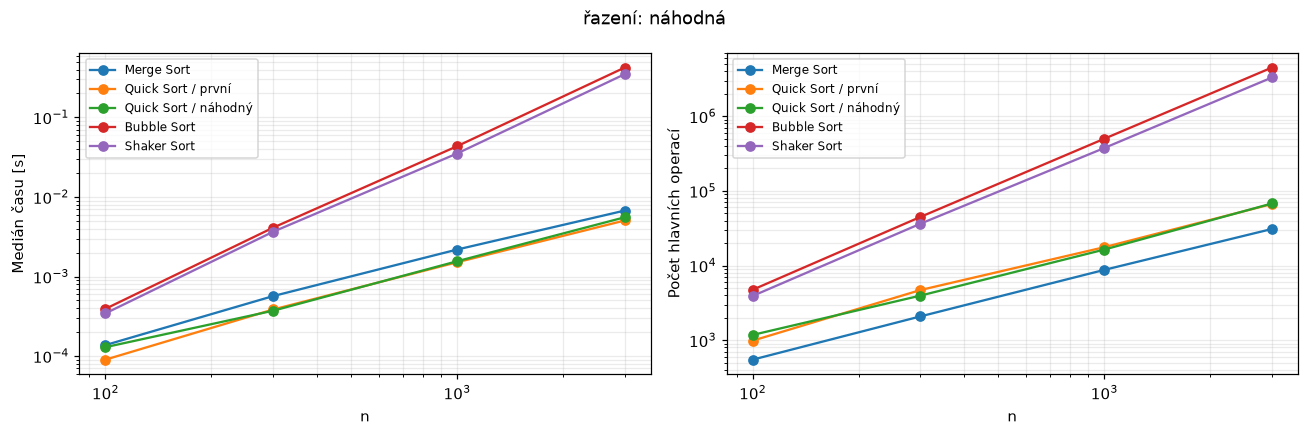

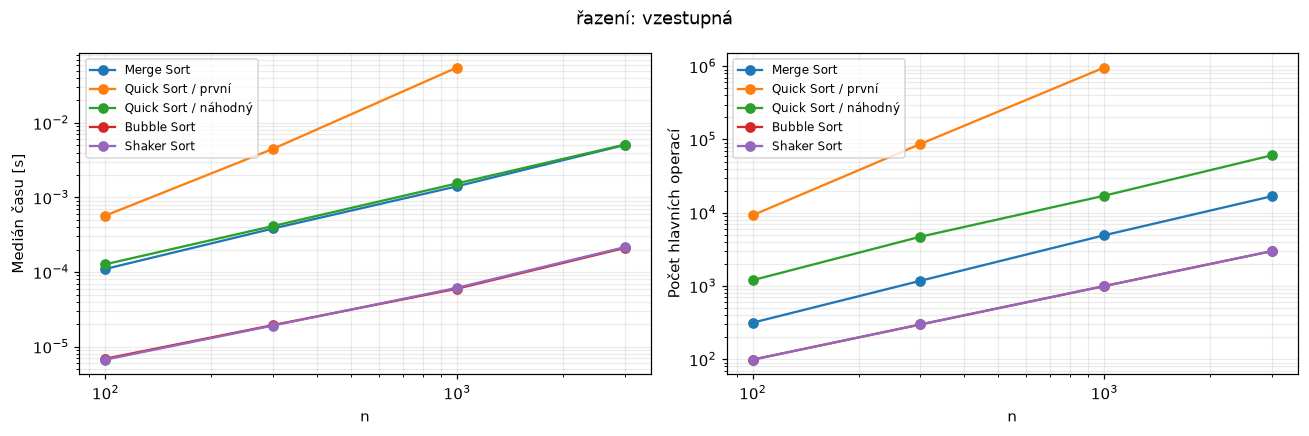

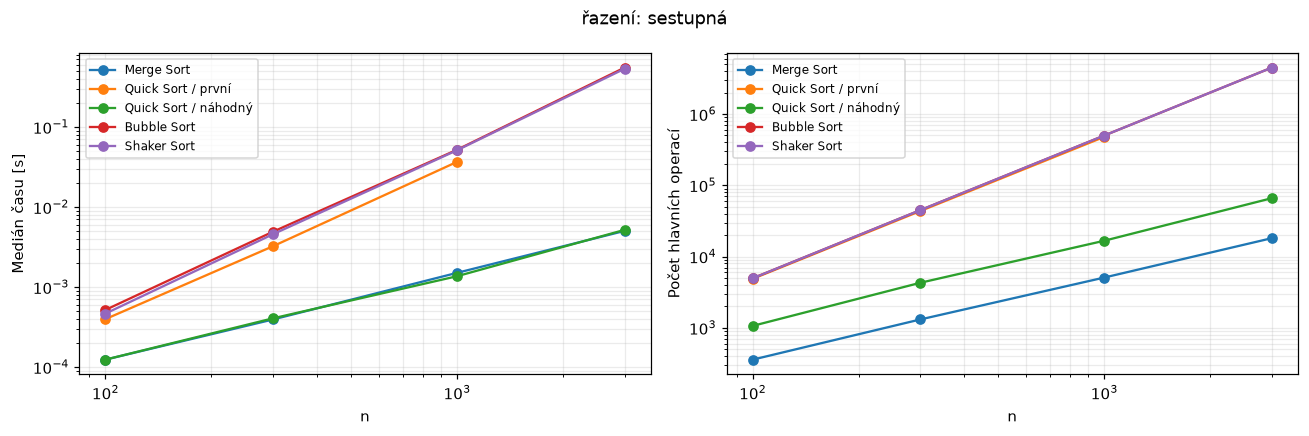

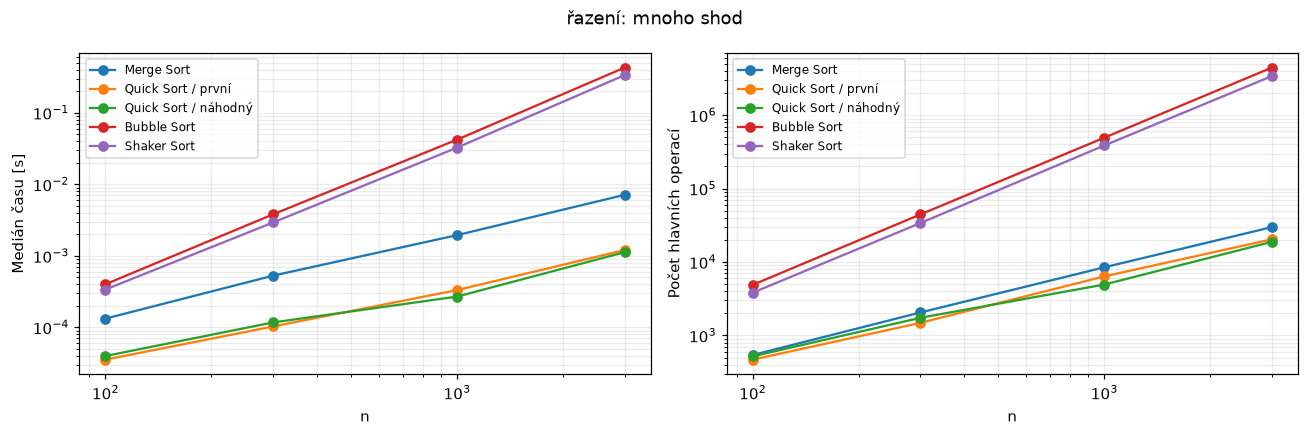

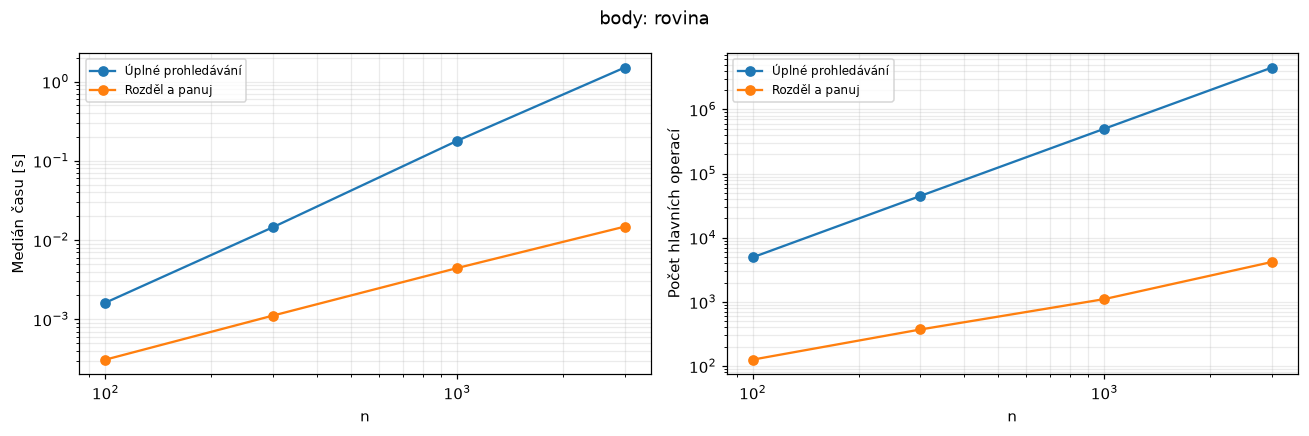

In [9]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
def plot_results(records, group, kind):
    subset = [r for r in records if r['group'] == group and r['input'] == kind and r['status'] == 'OK']
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name in dict.fromkeys(r['algorithm'] for r in subset):
        data = sorted((r for r in subset if r['algorithm'] == name), key=lambda r: r['n'])
        for ax, field in zip(axes, ('seconds', 'operations')):
            ax.plot([r['n'] for r in data], [r[field] for r in data], 'o-', label=name)
    for ax, label in zip(axes, ('Medián času [s]', 'Počet hlavních operací')):
        ax.set(xscale='log', yscale='log', xlabel='n', ylabel=label)
        ax.grid(True, which='both', alpha=.25)
        ax.legend(fontsize=8)
    fig.suptitle(f'{group}: {kind}')
    fig.tight_layout()
    plt.show()
for kind in ('náhodná', 'vzestupná', 'sestupná', 'mnoho shod'):
    plot_results(rows, 'řazení', kind)
plot_results(rows, 'body', 'rovina')


## Růst počtu operací
Pro největší úspěšný vstup uvádíme poměry k n² a n log₂ n a empirický exponent mezi dvěma největšími úspěšnými vstupy: log(C₂/C₁)/log(n₂/n₁). Exponent blízký 2 ukazuje kvadratický růst; u n log n bude mírně nad 1. Jde o konečná měření, nikoli důkaz složitosti.

In [10]:
growth = []
keys = dict.fromkeys((r['group'], r['algorithm'], r['input']) for r in rows)
for group, name, kind in keys:
    data = sorted([r for r in rows if (r['group'], r['algorithm'], r['input']) == (group, name, kind) and r['status'] == 'OK'], key=lambda r:r['n'])
    if len(data) < 2: continue
    a, b = data[-2:]
    n, count = b['n'], b['operations']
    growth.append(dict(algorithm=name, input=kind, n=n,
                       exponent=math.log(count/a['operations'])/math.log(n/a['n']),
                       C_n2=count/n**2, C_nlogn=count/(n*math.log2(n))))
show_table(growth, ['algorithm', 'input', 'n', 'exponent', 'C_n2', 'C_nlogn'])
failed = [r for r in rows if r['status'] != 'OK']
print('Počet běhů ukončených limitem rekurze:', len(failed))


| algorithm | input | n | exponent | C_n2 | C_nlogn |
| --- | --- | --- | --- | --- | --- |
| Merge Sort | náhodná | 3000 | 1.14946 | 0.00343478 | 0.892092 |
| Quick Sort / první | náhodná | 3000 | 1.21247 | 0.007415 | 1.92585 |
| Quick Sort / náhodný | náhodná | 3000 | 1.29506 | 0.00754489 | 1.95958 |
| Bubble Sort | náhodná | 3000 | 2.00028 | 0.499327 | 129.687 |
| Shaker Sort | náhodná | 3000 | 1.98053 | 0.367307 | 95.3982 |
| Merge Sort | vzestupná | 3000 | 1.11714 | 0.00186978 | 0.485625 |
| Quick Sort / první | vzestupná | 1000 | 1.99497 | 0.959396 | 96.269 |
| Quick Sort / náhodný | vzestupná | 3000 | 1.15628 | 0.00676211 | 1.75628 |
| Bubble Sort | vzestupná | 3000 | 1.00061 | 0.000333222 | 0.0865456 |
| Shaker Sort | vzestupná | 3000 | 1.00061 | 0.000333222 | 0.0865456 |
| Merge Sort | sestupná | 3000 | 1.15985 | 0.00201444 | 0.523198 |
| Quick Sort / první | sestupná | 1000 | 1.99012 | 0.478299 | 47.9941 |
| Quick Sort / náhodný | sestupná | 3000 | 1.25359 | 0.00733744 | 1.90571 |
| Bubble Sort | sestupná | 3000 | 2.00061 | 0.499833 | 129.818 |
| Shaker Sort | sestupná | 3000 | 2.00061 | 0.499833 | 129.818 |
| Merge Sort | mnoho shod | 3000 | 1.14854 | 0.00332067 | 0.862455 |
| Quick Sort / první | mnoho shod | 3000 | 1.05813 | 0.00226478 | 0.588216 |
| Quick Sort / náhodný | mnoho shod | 3000 | 1.21928 | 0.00209267 | 0.543515 |
| Bubble Sort | mnoho shod | 3000 | 2.00314 | 0.495209 | 128.617 |
| Shaker Sort | mnoho shod | 3000 | 1.98239 | 0.379047 | 98.4475 |
| Úplné prohledávání | rovina | 3000 | 2.00061 | 0.499833 | 129.818 |
| Rozděl a panuj | rovina | 3000 | 1.2137 | 0.000466222 | 0.121089 |

Počet běhů ukončených limitem rekurze: 2


## Interpretace výsledků a odpovědi
- **Merge Sort:** na každé úrovni slučuje celkem n prvků a má logaritmickou hloubku. Čas je Θ(n log n), dodatečná paměť Θ(n). Při shodě bere zleva; kontrola záznamů výše potvrzuje stabilitu.
- **Bubble Sort:** na náhodných a sestupných datech očekáváme Θ(n²) porovnání. Díky předčasnému ukončení má na vzestupných datech pouze n−1 porovnání, tedy Θ(n). Shaker Sort má obdobnou asymptotiku, ale prochází oběma směry.
- **Quick Sort, první pivot:** seřazený vstup rozděluje silně nevyváženě; u různých hodnot vede k Θ(n²) a hloubce Θ(n). U zde generovaných celých čísel mohou být duplicity, které část hladin odstraní. Pro velká seřazená data může Python vyvolat `RecursionError`; tabulka tento výsledek zachovává.
- **Quick Sort, náhodný pivot:** očekávaný čas je O(n log n), nejhorší zůstává O(n²). Náhodná volba omezuje závislost na původním pořadí. Naměřené časy zahrnují vytvoření generátoru pivotů. Třícestné dělení vyřadí všechny shody najednou; pro stejné hodnoty je práce Θ(n), pro nejvýše 10 různých hodnot je počet hladin omezen počtem klíčů. Poměry operací proto nemusí odpovídat n log n.
- **Nejbližší dvojice:** úplné prohledávání má přesně n(n−1)/2 výpočtů vzdáleností. Metoda rozděl a panuj udržuje y-pořadí a zkoumá nejvýše sedm následníků v pásu: O(n log n) času a O(n) pomocné paměti. Počet samotných vzdáleností nezahrnuje řazení a může růst pomaleji než celkový čas.
- **Kdy vítězí rozděl a panuj:** na větších datech převáží menší počet operací; u malých dat mají význam režie rekurze, vytváření seznamů a volání funkcí. Optimalizovaný Bubble Sort na již seřazeném vstupu může být rychlejší. Časy závisí na počítači a zátěži, proto používáme medián sedmi běhů.

Pomocné seznamy použitého Quick Sortu mohou v nevyváženém případě vyžadovat až O(n²) živé paměti. Nejde o in-place implementaci. Experimenty všech algoritmů používají stejné vstupy; výsledky s chybou nelze porovnávat jako dokončené běhy.

## Rozšíření: Karatsuba versus školní násobení
Oba algoritmy ověřujeme operátorem `*`. Měříme 10, 30, 100, 300 a 1000 číslic, vždy stejnou dvojici pro obě metody. Generování a kontrola jsou mimo měřený úsek.

| algorithm | digits | seconds | correct |
| --- | --- | --- | --- |
| Školní | 10 | 1.50001e-05 | True |
| Karatsuba | 10 | 2.20998e-05 | True |
| Školní | 30 | 5.61001e-05 | True |
| Karatsuba | 30 | 8.64002e-05 | True |
| Školní | 100 | 0.0005402 | True |
| Karatsuba | 100 | 0.0007367 | True |
| Školní | 300 | 0.0052378 | True |
| Karatsuba | 300 | 0.0047296 | True |
| Školní | 1000 | 0.0582668 | True |
| Karatsuba | 1000 | 0.0287783 | True |

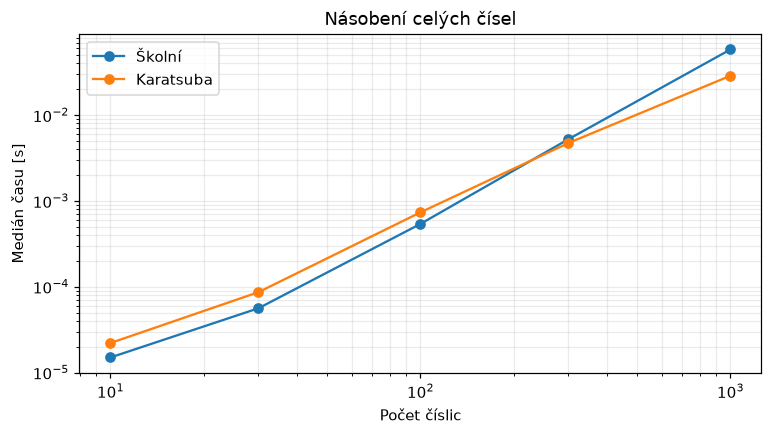

Poměr času školní / Karatsuba pro 1000 číslic: 2.02


In [11]:
multiplication_rows = main.multiplication_experiments()
main.save_csv(multiplication_rows, Path('nasobeni.csv'))
show_table(multiplication_rows, ['algorithm', 'digits', 'seconds', 'correct'])
fig, ax = plt.subplots(figsize=(8, 4))
for name in ('Školní', 'Karatsuba'):
    data = [r for r in multiplication_rows if r['algorithm'] == name]
    ax.plot([r['digits'] for r in data], [r['seconds'] for r in data], 'o-', label=name)
ax.set(xscale='log', yscale='log', xlabel='Počet číslic', ylabel='Medián času [s]', title='Násobení celých čísel')
ax.grid(True, which='both', alpha=.25); ax.legend()
plt.show()
last = {r['algorithm']: r['seconds'] for r in multiplication_rows if r['digits'] == 1000}
print(f"Poměr času školní / Karatsuba pro 1000 číslic: {last['Školní']/last['Karatsuba']:.2f}")


Karatsuba nahrazuje čtyři součiny polovičních čísel třemi: T(n)=3T(n/2)+O(n), tedy O(n^log₂3) ≈ O(n^1,585). Školní algoritmus provádí Θ(n²) násobení číslic. U malých čísel může převážit režie rekurze. Tato Python implementace navíc převádí čísla na řetězce a používá velká celá čísla, takže naměřený čas není čistým modelem jednotkových číslicových operací. Operátor `*` slouží jako kontrola správnosti, nikoli jako implementace celého násobení v našich algoritmech (Karatsuba jej používá v základním případě a pro posun řádu).